# Videos with `robotdesigner`: record, save, show

Render a rollout in the robosuite `Lift` scene and turn it into an MP4 or GIF, then save it or show it right here.
Recording is Gymnasium-style: the live state is rendered while the rollout runs. See `docs/viz.md` for the full guide.

Install first: `pip install -e ".[env,robosuite,viz]"` (Pillow writes GIFs, imageio-ffmpeg writes MP4s).
Rendering needs an OpenGL context; on a headless Linux machine MuJoCo needs EGL, set **before mujoco is imported**.

In [1]:
import io
import os
import sys

# Headless Linux (no DISPLAY, e.g. a cluster node): use EGL. This must happen before mujoco is imported;
# if mujoco was already imported in this kernel, set MUJOCO_GL=egl in the environment and restart the kernel.
if sys.platform == "linux" and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")

import numpy as np
import torch
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image

from robotdesigner import make_env
from robotdesigner.config import (
    ControlConfig, EnvConfig, FixedGains, MujocoOptions, SimConfig, TaskConfig, chain,
)
from robotdesigner.config import kinematics as kin
from robotdesigner.tasks.robosuite import ReachObject, RobosuiteParams, default_mount
from robotdesigner.viz import VIEWS, Clip, FrameRecorder, annotate, record_rollout, tile, tile_clips


def show(image, quality=90):
    """Show an RGB array as one small JPEG (keeps the notebook file small)."""
    buf = io.BytesIO()
    Image.fromarray(image).save(buf, format="JPEG", quality=quality)
    display(IPImage(data=buf.getvalue(), format="jpeg"))

## 1. An environment

The `Lift` scene with a `ReachObject` objective: success is the end effector coming within `tolerance` of the cube's
centre. The arm's length and joint count are arguments so that section 6 can compare embodiments.

In [2]:
def make_config(n=3, length=0.9, num_envs=4, horizon=100, tolerance=0.08):
    arm = chain(
        n=n, axes="z" + "y" * (n - 1), total_length=length, total_mass=3.0, radius=0.03,
        damping=0.5, armature=0.01, frictionloss=0.0, effort_limit=50.0, range=(-2.5, 2.5),
        base_pose=default_mount("Lift"),               # where robosuite mounts a stock arm in this scene
    )
    return EnvConfig(
        robot=arm,
        control=ControlConfig("joint_pos_abs", FixedGains(kp=60.0, kd=6.0), action_scale=None),
        task=TaskConfig(
            id="robosuite/Lift", horizon=horizon, success_tolerance=None, target_region=None,
            params=RobosuiteParams({}, ReachObject("cube", tolerance), reset_noise=0.0, terminate_on_success=False),
        ),
        sim=SimConfig(backend="mujoco", num_envs=num_envs, device="cpu", dt=0.002, integrator="euler",
                      control_freq=50, seed=0, scene="empty"),
        backend_options=MujocoOptions(self_collision=False),
    )


import logging

env = make_env(make_config(num_envs=4))            # the first scene load imports robosuite; its warnings are harmless
logging.getLogger("robosuite_logs").setLevel(logging.WARNING)       # it logs an INFO line for every scene it loads
env.reset()
env.batch_size, env.cfg.sim.control_freq

[robosuite WARNING] No private macro file found! (macros.py:53)
[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)
[robosuite WARNING] To setup, run: python <site-packages>/robosuite/scripts/setup_macros.py (macros.py:55)
[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)
[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly, otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)
[robosuite INFO] Loading controller configuration from: <site-packages>/robosuite/controllers/config/robots/default_panda.json (composite_controller_factory.py:121)
[robosuite INFO] Loading controller configuration from: <site-packages>/robosuite/controllers/config/robo

(torch.Size([4]), 50.0)

## 2. One frame

`env.render()` returns the live state of one env as a `uint8 (H, W, 3)` array (like Gymnasium's `rgb_array`). A frame
shows the whole MuJoCo scene: the floor, the table, the cube and the arm. Task state that is *not* in the model would be
drawn as overlays by the task; a robosuite scene has none, the cube is a body of the model. Rendering never changes the
simulation.

(240, 320, 3) uint8


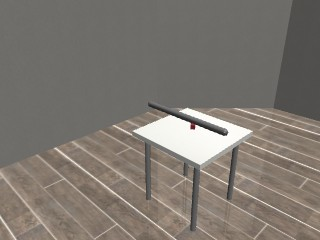

In [3]:
frame = env.render(size=(240, 320))          # env 0, default "iso" view
print(frame.shape, frame.dtype)
show(frame)

## 3. Record a rollout and see it

Any `policy(td) -> td` works, for example a trained one. Here a small scripted policy takes damped least-squares steps on
the arm's Jacobian (from the numpy kinematics oracle) towards a point 6 cm above the cube, and integrates them into the
joint targets. A small gain keeps it smooth. `rs_sideview` is a camera of the robosuite arena.

In [4]:
def make_cube_policy(env, hover=0.06, gain=0.15, max_step=0.05, damping=0.05):
    arm, rng = env.cfg.robot, env.interface.joint_range
    scale, offset = (rng[:, 1] - rng[:, 0]) / 2.0, (rng[:, 1] + rng[:, 0]) / 2.0   # joint_pos_abs: ctrl = a * scale + offset
    state = {"q_cmd": None}

    def policy(td):
        q = td["proprio", "qpos"].double().numpy()                                   # (N, n)
        if state["q_cmd"] is None:
            state["q_cmd"] = q.copy()
        fresh = (td["episode_step"].reshape(-1) == 0).numpy()                        # rows that were just reset
        state["q_cmd"][fresh] = q[fresh]
        goal = td["task", "cube_pos"] + torch.tensor([0.0, 0.0, hover])             # above the cube, base frame
        err = np.clip((goal - td["task", "ee_pos"]).double().numpy(), -max_step, max_step)   # (N, 3)
        base = kin.forward_ee_batch(arm, q)
        J = np.stack([(kin.forward_ee_batch(arm, q + 1e-4 * np.eye(arm.n)[j]) - base) / 1e-4
                      for j in range(arm.n)], axis=-1)                               # (N, 3, n)
        Jt = J.transpose(0, 2, 1)
        dq = (Jt @ np.linalg.solve(J @ Jt + damping**2 * np.eye(3), err[..., None]))[..., 0]
        state["q_cmd"] = np.clip(state["q_cmd"] + gain * dq, rng[:, 0], rng[:, 1])
        td.set("action", torch.as_tensor((state["q_cmd"] - offset) / scale, dtype=torch.float32))
        return td

    return policy


policy = make_cube_policy(env)
traj, clip = record_rollout(env, 100, policy, env_index=0, every=3, size=(150, 200), camera="rs_sideview")
print(clip)
print("reached the cube, per env:", traj["next", "success"].any(dim=1).squeeze(-1).tolist())
clip          # the last expression of a cell shows itself: an MP4 here, a GIF if MP4 support is missing

Clip(35 frames, 150x200, 16.6667 fps, 2.10 s)
reached the cube, per env: [True, True, True, True]


Clip(35 frames, 150x200, 16.6667 fps, 2.10 s)

`every=3` renders every third control step, so the clip plays at `control_freq / every` = 16.7 fps, in real time. It holds
the initial state, every third state and the final state.

## 4. Save it, or show it in another format

`clip.save(path)` takes the format from the suffix. `clip.show("gif")` shows a GIF inline instead of the MP4.
GIFs are much larger (below, the first 12 frames of the clip, to keep this notebook small); GIF delays come in 10 ms
steps, so only some rates are exact (50, 25, 20, 16.7, 12.5, 10 fps; a warning says when a rate is not).

{'scene.mp4': '10 kB', 'scene.gif': '694 kB'}



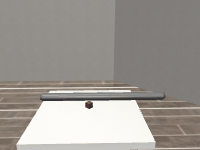

In [5]:
import tempfile
from pathlib import Path

out = Path(tempfile.mkdtemp(prefix="robotdesigner_viz_"))
files = [clip.save(out / "scene.mp4"), clip.save(out / "scene.gif")]
print({f.name: f"{f.stat().st_size / 1e3:.0f} kB" for f in files})
Clip(clip.frames[:12], clip.fps).show("gif")

## 5. Several envs, and other cameras

`env_index` takes an int, a list or `"all"`; several envs are tiled and labelled. A camera is a named view (`iso`,
`front`, `side`, `top`; framed on the robot's workspace), a `CameraSpec`, or a camera of the model: the cameras of the
robosuite arena are `rs_frontview`, `rs_birdview`, `rs_agentview` and `rs_sideview`.

In [6]:
traj, clip_all = record_rollout(env, 100, policy, env_index="all", every=3, size=(120, 160), camera="rs_sideview")
print(clip_all)
clip_all

Clip(35 frames, 246x326, 16.6667 fps, 2.10 s)


Clip(35 frames, 246x326, 16.6667 fps, 2.10 s)

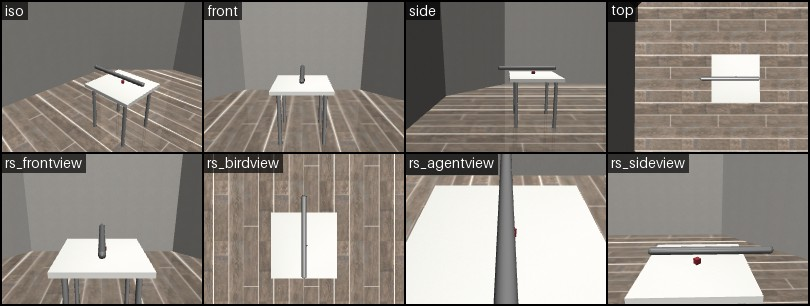

In [7]:
env.reset()
views = [annotate(env.render(0, camera=v, size=(150, 200)), v)
         for v in [*VIEWS, "rs_frontview", "rs_birdview", "rs_agentview", "rs_sideview"]]
show(tile(views, ncols=4))

## 6. Comparing embodiments

Give every embodiment the **same camera**, so that the frames share a scale; with each embodiment's own default camera a
short arm would look as large as a long one. A fixed camera of the arena (`rs_sideview`) does that here, and
`auto_camera(*configs)` returns one framing for any set of configs. The **same scene** comes for free: the task draws the
cube from its own random stream, which does not depend on the robot, so with the same seed every embodiment gets the same
cube (the printed position is identical). Then tile the clips side by side.

The printed closest approach shows how each embodiment did with the same scripted policy and cube. The policy is not tuned
per embodiment, so the numbers say how this policy fares on each arm, not how good the arm is.

In [8]:
configs = {f"n={n}  L={L}": make_config(n=n, length=L, num_envs=1, horizon=100) for n, L in [(2, 0.6), (3, 0.9), (5, 1.4)]}

clips = []
for name, cfg in configs.items():
    e = make_env(cfg)
    traj, c = record_rollout(e, 100, make_cube_policy(e), camera="rs_sideview", every=3, size=(120, 160), label=False)
    dist = (traj["next", "task", "cube_pos"] - traj["next", "task", "ee_pos"]).norm(dim=-1).min().item()
    print(f"{name}: robot_hash={e.robot_hash}  cube={traj['task', 'cube_pos'][0, 0].numpy().round(4)}  "
          f"closest approach {dist:.3f} m  reached={bool(traj['next', 'success'].any())}")
    clips.append(c)
    e.close()

tile_clips(clips, labels=list(configs), ncols=3)

n=2  L=0.6: robot_hash=fec3925ce4f1  cube=[ 0.5388  0.029  -0.0808]  closest approach 0.077 m  reached=True
n=3  L=0.9: robot_hash=bf7bdacb56c4  cube=[ 0.5388  0.029  -0.0808]  closest approach 0.059 m  reached=True
n=5  L=1.4: robot_hash=372e99813f7c  cube=[ 0.5388  0.029  -0.0808]  closest approach 0.132 m  reached=False


Clip(35 frames, 124x488, 16.6667 fps, 2.10 s)

## 7. Your own loop

`record_rollout` wraps `FrameRecorder`, which is a rollout callback. TorchRL calls a callback after every step except
the last (and except the step that stops a rollout early), so the first and last frames are captured by hand.

In [9]:
rec = FrameRecorder(env, env_index=[0, 1], every=3, size=(120, 160), camera="rs_sideview")
td = env.reset()
rec.capture(0)                                                    # the initial state
traj = env.rollout(40, policy, callback=rec, auto_reset=False, tensordict=td)
rec.finish(traj.shape[-1])                                        # the final state
rec.clip()

Clip(15 frames, 124x326, 16.6667 fps, 0.90 s)

In [10]:
env.close()          # frees the renderer